In [1]:
import pandas as pd
df = pd.read_csv("DelayedFlights.csv")
df.head()

,Unnamed: 0,Year,Month,DayofMonth,DayOfWeek,DepTime,CRSDepTime,ArrTime,CRSArrTime,UniqueCarrier,...,TaxiIn,TaxiOut,Cancelled,CancellationCode,Diverted,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
0,0,2008,1,3,4,2003.0,1955,2211.0,2225,WN,...,4.0,8.0,0,N,0,NaN,NaN,NaN,NaN,NaN
1,1,2008,1,3,4,754.0,735,1002.0,1000,WN,...,5.0,10.0,0,N,0,NaN,NaN,NaN,NaN,NaN
2,2,2008,1,3,4,628.0,620,804.0,750,WN,...,3.0,17.0,0,N,0,NaN,NaN,NaN,NaN,NaN
3,4,2008,1,3,4,1829.0,1755,1959.0,1925,WN,...,3.0,10.0,0,N,0,2.0,0.0,0.0,0.0,32.0
4,5,2008,1,3,4,1940.0,1915,2121.0,2110,WN,...,4.0,10.0,0,N,0,NaN,NaN,NaN,NaN,NaN


In [2]:
print(df.shape)
print(df.columns.tolist())

(1936758, 30)
['Unnamed: 0', 'Year', 'Month', 'DayofMonth', 'DayOfWeek', 'DepTime', 'CRSDepTime', 'ArrTime', 'CRSArrTime', 'UniqueCarrier', 'FlightNum', 'TailNum', 'ActualElapsedTime', 'CRSElapsedTime', 'AirTime', 'ArrDelay', 'DepDelay', 'Origin', 'Dest', 'Distance', 'TaxiIn', 'TaxiOut', 'Cancelled', 'CancellationCode', 'Diverted', 'CarrierDelay', 'WeatherDelay', 'NASDelay', 'SecurityDelay', 'LateAircraftDelay']


In [3]:
df[["ArrDelay", "DepDelay", "Distance", "AirTime", "TaxiIn", "TaxiOut"]].describe()

,ArrDelay,DepDelay,Distance,AirTime,TaxiIn,TaxiOut
count,1.928371e+06,1.936758e+06,1.936758e+06,1.928371e+06,1.929648e+06,1.936303e+06
mean,4.219988e+01,4.318518e+01,7.656862e+02,1.082771e+02,6.812975e+00,1.823220e+01
std,5.678472e+01,5.340250e+01,5.744797e+02,6.864261e+01,5.273595e+00,1.433853e+01
min,-1.090000e+02,6.000000e+00,1.100000e+01,0.000000e+00,0.000000e+00,0.000000e+00
25%,9.000000e+00,1.200000e+01,3.380000e+02,5.800000e+01,4.000000e+00,1.000000e+01
50%,2.400000e+01,2.400000e+01,6.060000e+02,9.000000e+01,6.000000e+00,1.400000e+01
75%,5.600000e+01,5.300000e+01,9.980000e+02,1.370000e+02,8.000000e+00,2.100000e+01
max,2.461000e+03,2.467000e+03,4.962000e+03,1.091000e+03,2.400000e+02,4.220000e+02


**Insight:** The mean arrival delay (about 42 min) is almost double the median (24 min), because a few extremely late flights (max 2,461 min) pull the mean up. The standard deviation (57 min) is larger than the mean, so delays vary a lot. The median describes a typical delay better.

In [4]:
print("Skewness:", df["ArrDelay"].skew())

Q1 = df["ArrDelay"].quantile(0.25)
Q3 = df["ArrDelay"].quantile(0.75)
IQR = Q3 - Q1
upper = Q3 + 1.5 * IQR
lower = Q1 - 1.5 * IQR
print("Upper bound:", upper)
print("Lower bound:", lower)
print("Outliers count:", ((df["ArrDelay"] > upper) | (df["ArrDelay"] < lower)).sum())

Skewness: 3.948780374309395
Upper bound: 126.5
Lower bound: -61.5
Outliers count: 137430


**Insight:** Skewness is 3.95, so the distribution is strongly right-skewed. Using the IQR method, 137,430 flights (about 7.1%) are outliers: delayed more than 126.5 min or early by more than 61.5 min.

In [5]:
delays = df["ArrDelay"].dropna()

print("P(delay > 30 min):", (delays > 30).mean())
print("P(delay > 60 min):", (delays > 60).mean())
print("P(delay > 120 min):", (delays > 120).mean())


P(delay > 30 min): 0.4306640164159283
P(delay > 60 min): 0.22774403888048514
P(delay > 120 min): 0.07880226367229128


**Insight:** Among these flights, 43.1% arrived more than 30 min late, 22.8% more than 60 min, and 7.9% more than 120 min. The probability drops quickly as the threshold increases, matching the right skew. All flights in this data already departed late, so these probabilities are conditional on a departure delay.

In [6]:
df["big_delay"] = (df["ArrDelay"] > 60).astype(int)
df.groupby("UniqueCarrier")["big_delay"].mean().sort_values(ascending=False)

UniqueCarrier
B6    0.315773
YV    0.313496
OH    0.287369
XE    0.281200
UA    0.277912
AA    0.260402
EV    0.260378
9E    0.260075
OO    0.258954
MQ    0.244356
FL    0.231777
CO    0.224502
NW    0.212166
DL    0.203356
US    0.191577
AS    0.175833
WN    0.144157
HA    0.118024
F9    0.112491
AQ    0.074667
Name: big_delay, dtype: float64

UniqueCarrier
WN    377602
AA    191865
MQ    141920
UA    141426
OO    132433
DL    114238
XE    103663
CO    100195
US     98425
EV     81877
NW     79108
FL     71284
YV     67063
B6     55315
OH     52657
9E     51885
AS     39293
F9     28269
HA      7490
AQ       750
Name: count, dtype: int64


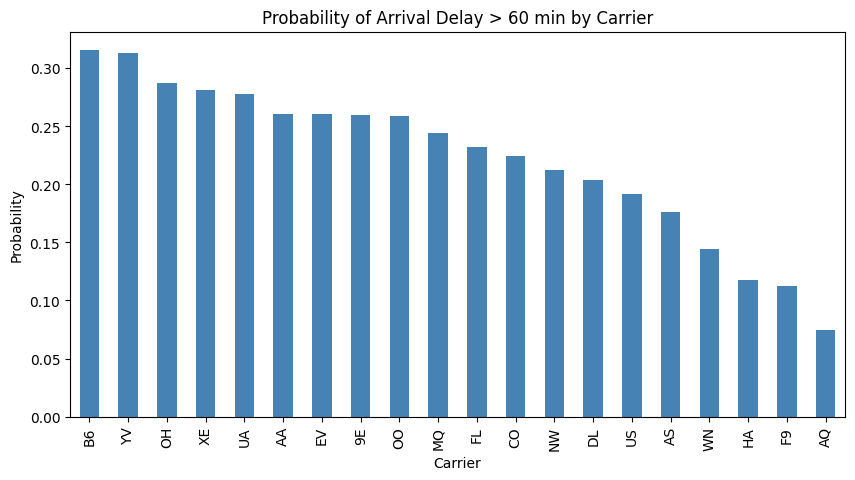

In [7]:
import matplotlib.pyplot as plt

print(df["UniqueCarrier"].value_counts())

prob = df.groupby("UniqueCarrier")["big_delay"].mean().sort_values(ascending=False)
prob.plot(kind="bar", figsize=(10, 5), color="steelblue")
plt.title("Probability of Arrival Delay > 60 min by Carrier")
plt.ylabel("Probability")
plt.xlabel("Carrier")
plt.show()

**Insight:** P(delay > 60 min | carrier) ranges from 7.5% (AQ) to 31.6% (B6), about a 4x difference, so UniqueCarrier looks like an important feature for modeling. This is a correlation, not proof of cause: the difference may come from the airports and routes each carrier serves.